# SEMMA Project: Predicting Student Performance in Mathematics

**Author:** Weihao Fu
**Course:** CMPE-255, Data Mining (Fall 2026)
**Assignment:** Data Mining process Assignment - crisp-dm etc. (SEMMA portion)

## Introduction

This notebook applies the **SEMMA** methodology (Sample, Explore, Modify, Model, Assess)
to a student performance prediction problem. The goal is to predict whether a student
**passes or fails** the final mathematics exam, so that at-risk students can be
identified early and given support.

**Dataset source:** UCI Machine Learning Repository, *Student Performance Data Set*
(Cortez & Silva, 2008), downloaded from
https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip
(file `student-mat.csv`, mathematics course, two Portuguese schools, 2005-2006).

**Target definition:** A student is labeled **pass** when the final grade `G3 >= 10`
and **fail** when `G3 < 10`. Grades in Portugal range from 0 to 20, and 10 is the
passing threshold. This binary target is created from `G3` and `G3` itself is then
excluded from the model inputs.

**Tools:** Python (pandas, scikit-learn, matplotlib, seaborn). No SAS is used;
the assignment lists a SAS trial only as an optional aid, and this project is
implemented entirely in Python.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
sns.set(style="whitegrid")
print("Libraries loaded.")

Libraries loaded.


## 1. Sample

SEMMA starts with **Sample**: selecting the data that will be mined.

The UCI Student Performance data set contains one row per student with 30
demographic, social, and school-related attributes plus three grade columns
(`G1` first-period grade, `G2` second-period grade, `G3` final grade).
We use the **mathematics** course file (`student-mat.csv`).

Sampling decision: the file is already a complete, modestly sized cohort
(395 students from two schools), so **no further subsampling is performed** —
using the full cohort avoids sampling bias. Instead, the data is split into a
stratified train/test set later (Section 3), which preserves the pass/fail
ratio in both parts. This is the standard sampling choice when the data set
is small and complete.

In [2]:
df = pd.read_csv("student-mat.csv", sep=";")
print("Shape (rows, columns):", df.shape)
print()
print("Column names:")
print(list(df.columns))
print()
print("Data types:")
print(df.dtypes.value_counts())
print()
print("First 5 rows:")
df.head()

Shape (rows, columns): (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
str      17
int64    16
Name: count, dtype: int64

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Explore

SEMMA's **Explore** phase examines the data: distributions, relationships,
anomalies, and the balance of the target variable.

Key questions: How many students pass? How are grades distributed? Which
variables look related to the final grade?

Target distribution (1 = pass, 0 = fail):
pass
1    265
0    130
Name: count, dtype: int64
Pass rate: 67.1%


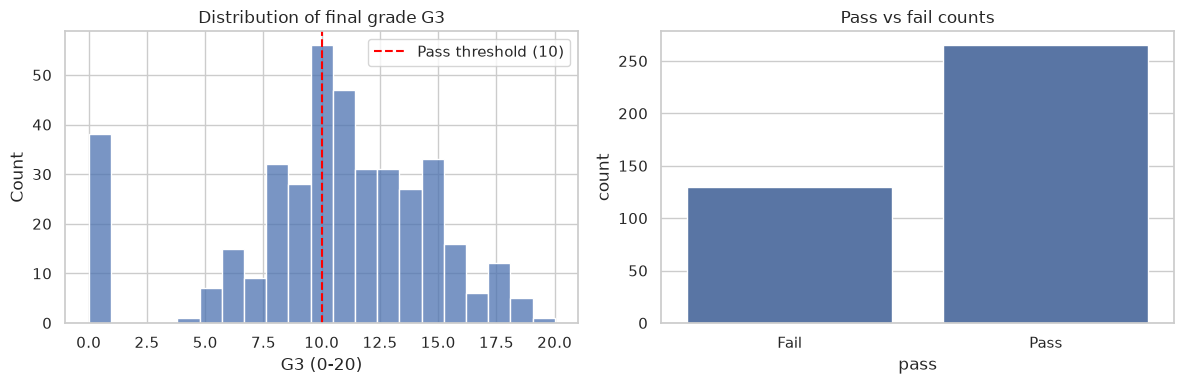

In [3]:
# Target construction: pass = G3 >= 10, fail = G3 < 10
df["pass"] = (df["G3"] >= 10).astype(int)
print("Target distribution (1 = pass, 0 = fail):")
print(df["pass"].value_counts())
print("Pass rate: %.1f%%" % (100 * df["pass"].mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["G3"], bins=21, kde=False, ax=axes[0])
axes[0].set_title("Distribution of final grade G3")
axes[0].set_xlabel("G3 (0-20)")
axes[0].axvline(10, color="red", linestyle="--", label="Pass threshold (10)")
axes[0].legend()
sns.countplot(x="pass", data=df, ax=axes[1])
axes[1].set_title("Pass vs fail counts")
axes[1].set_xticklabels(["Fail", "Pass"])
plt.tight_layout()
plt.show()

Numeric summary:


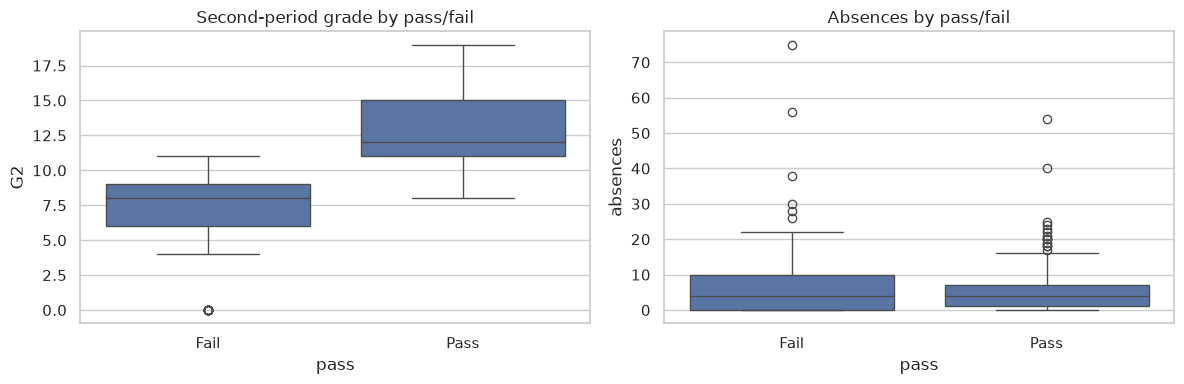

In [4]:
print("Numeric summary:")
df.describe().T[["mean", "std", "min", "max"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="pass", y="G2", data=df, ax=axes[0])
axes[0].set_title("Second-period grade by pass/fail")
axes[0].set_xticklabels(["Fail", "Pass"])
sns.boxplot(x="pass", y="absences", data=df, ax=axes[1])
axes[1].set_title("Absences by pass/fail")
axes[1].set_xticklabels(["Fail", "Pass"])
plt.tight_layout()
plt.show()

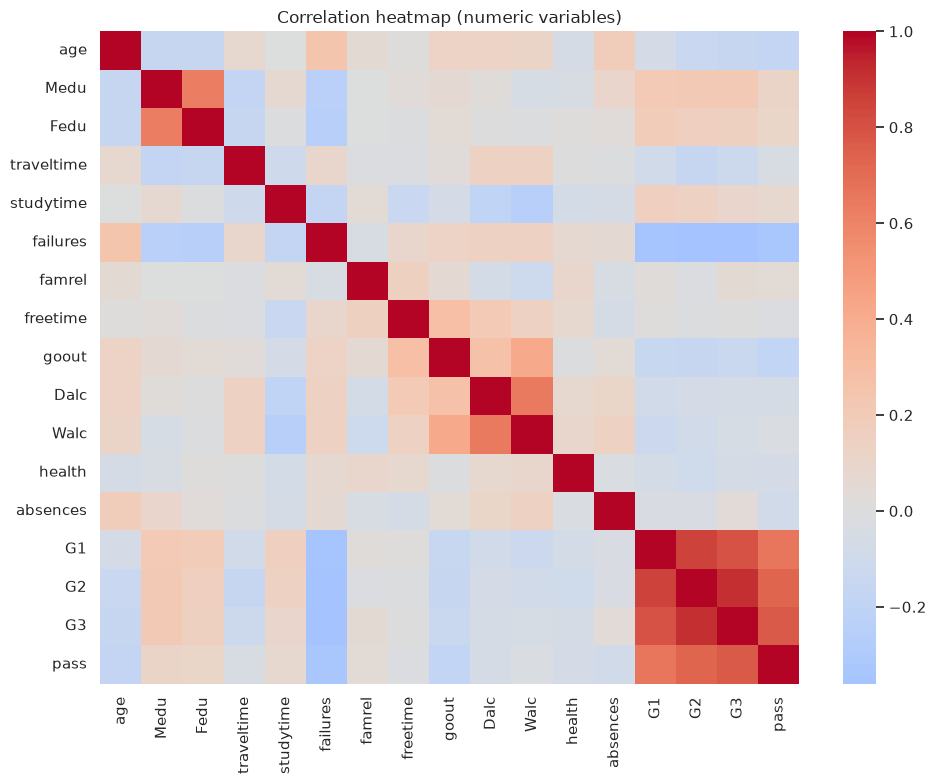

Correlations with final grade G3 (top 8 by absolute value):
G2          0.904868
G1          0.801468
pass        0.770042
failures   -0.360415
Medu        0.217147
age        -0.161579
Fedu        0.152457
goout      -0.132791
Name: G3, dtype: float64


In [5]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap (numeric variables)")
plt.tight_layout()
plt.show()

print("Correlations with final grade G3 (top 8 by absolute value):")
print(corr["G3"].drop("G3").reindex(
    corr["G3"].drop("G3").abs().sort_values(ascending=False).index).head(8))

### Exploration findings

- The data set is **moderately imbalanced**: about two thirds of students pass
  and one third fail, so accuracy alone is not enough — precision, recall, and
  ROC-AUC are reported in Section 5.
- `G1` and `G2` (earlier grades) are by far the strongest correlates of `G3`,
  which is expected: earlier performance predicts later performance.
- Absences, study time, and parental education show weaker but real
  relationships with the outcome.
- No missing values were found (verified in Section 3), so no imputation
  strategy is needed; the Modify phase therefore focuses on encoding,
  feature engineering, and splitting.

## 3. Modify

SEMMA's **Modify** phase prepares the data for modeling: handling missing
values, transforming variables, creating new features, and splitting the
data into training and test sets.

Steps performed here:
1. Verify missing values (none found in this data set).
2. Engineer two interpretable features: `parent_edu` (average of mother's and
   father's education levels) and `alc_total` (weekday + weekend alcohol
   consumption).
3. One-hot encode the categorical variables and standardize the numeric
   variables (inside the model pipelines, so the test set is never used to
   fit the transformers).
4. Stratified 80/20 train/test split, preserving the pass/fail ratio.

In [6]:
print("Total missing values:", int(df.isna().sum().sum()))
print("Missing values per column (columns with any missing):")
print(df.isna().sum()[df.isna().sum() > 0])

# Feature engineering
df["parent_edu"] = (df["Medu"] + df["Fedu"]) / 2.0
df["alc_total"] = df["Dalc"] + df["Walc"]

# Inputs: all columns except the grades used to build the target (G3)
# and the target itself. G1 and G2 are kept as predictors (see interpretation
# in Section 5: an early-warning model would exclude them).
X = df.drop(columns=["G3", "pass"])
y = df["pass"]

categorical = X.select_dtypes(include=["object"]).columns.tolist()
numeric = X.select_dtypes(include=[np.number]).columns.tolist()
print("Categorical features (%d):" % len(categorical), categorical)
print("Numeric features (%d):" % len(numeric), numeric)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train size:", X_train.shape, " Test size:", X_test.shape)
print("Train pass rate: %.3f  Test pass rate: %.3f"
      % (y_train.mean(), y_test.mean()))

Total missing values: 0
Missing values per column (columns with any missing):
Series([], dtype: int64)
Categorical features (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numeric features (17): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'parent_edu', 'alc_total']
Train size: (316, 34)  Test size: (79, 34)
Train pass rate: 0.671  Test pass rate: 0.671


## 4. Model

SEMMA's **Model** phase fits predictive models to the training data.
Three classifiers are compared:

1. **Logistic Regression** — a simple, interpretable linear baseline.
2. **Random Forest** — an ensemble of decision trees that captures
   non-linear relationships and provides feature importances.
3. **Gradient Boosting** — a sequential ensemble that often achieves the
   best accuracy on tabular data.

Categorical features are one-hot encoded and numeric features are
standardized inside each pipeline, so preprocessing is fit only on the
training data.

In [7]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocess),
        ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained.")

results = {}
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pred": pred,
        "proba": proba,
    }
    print("%s: accuracy=%.3f precision=%.3f recall=%.3f ROC-AUC=%.3f"
          % (name, results[name]["accuracy"], results[name]["precision"],
             results[name]["recall"], results[name]["roc_auc"]))

Logistic Regression trained.


Random Forest trained.


Gradient Boosting trained.
Logistic Regression: accuracy=0.873 precision=0.957 recall=0.849 ROC-AUC=0.948
Random Forest: accuracy=0.873 precision=0.957 recall=0.849 ROC-AUC=0.936
Gradient Boosting: accuracy=0.886 precision=0.958 recall=0.868 ROC-AUC=0.940


## 5. Assess

SEMMA's **Assess** phase evaluates the models and interprets the results.
Accuracy alone can mislead on an imbalanced target, so precision, recall,
the confusion matrix, and ROC-AUC are reported together. A model is useful
for early intervention only if it catches failing students (high recall on
the fail class) without flagging too many passing students (precision).

In [8]:
summary = pd.DataFrame([
    {"Model": name,
     "Accuracy": round(v["accuracy"], 3),
     "Precision": round(v["precision"], 3),
     "Recall": round(v["recall"], 3),
     "ROC-AUC": round(v["roc_auc"], 3)}
    for name, v in results.items()
]).sort_values("ROC-AUC", ascending=False)
summary

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.873,0.957,0.849,0.948
2,Gradient Boosting,0.886,0.958,0.868,0.940
1,Random Forest,0.873,0.957,0.849,0.936


Best model by ROC-AUC: Logistic Regression

              precision    recall  f1-score   support

        Fail       0.75      0.92      0.83        26
        Pass       0.96      0.85      0.90        53

    accuracy                           0.87        79
   macro avg       0.85      0.89      0.86        79
weighted avg       0.89      0.87      0.88        79



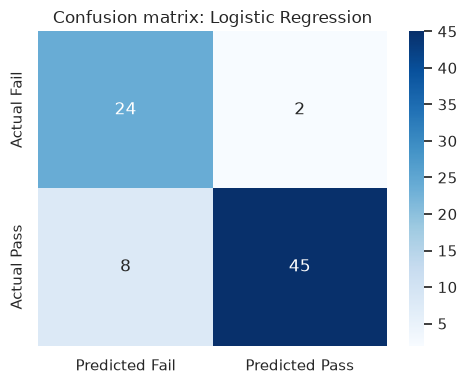

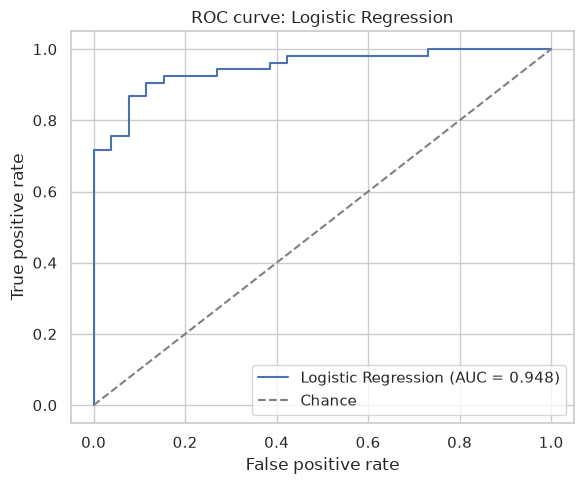

In [9]:
best_name = summary.iloc[0]["Model"]
best_pred = results[best_name]["pred"]
best_proba = results[best_name]["proba"]
print("Best model by ROC-AUC:", best_name)
print()
print(classification_report(y_test, best_pred,
                            target_names=["Fail", "Pass"]))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Fail", "Predicted Pass"],
            yticklabels=["Actual Fail", "Actual Pass"])
plt.title("Confusion matrix: " + best_name)
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, best_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label="%s (AUC = %.3f)"
         % (best_name, results[best_name]["roc_auc"]))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve: " + best_name)
plt.legend()
plt.tight_layout()
plt.show()

Top 10 features by Random Forest importance:
G2            0.335808
G1            0.183586
failures      0.046828
absences      0.037005
age           0.023185
goout         0.020495
alc_total     0.017508
parent_edu    0.016287
health        0.015420
Walc          0.014083
dtype: float64


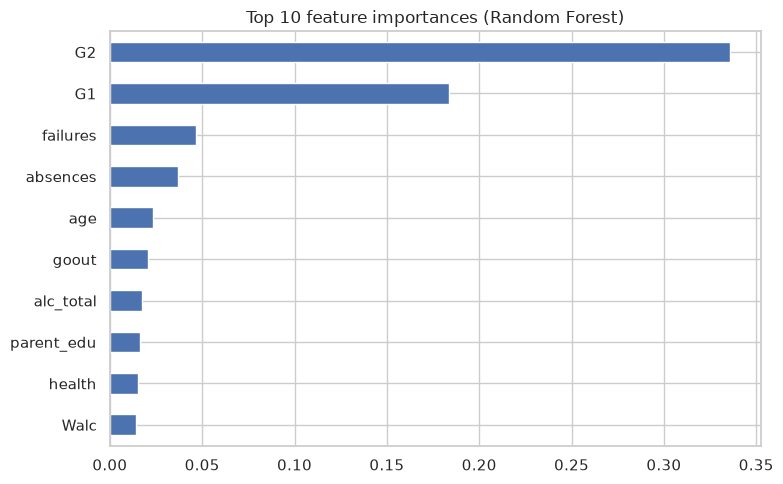

In [10]:
# Which features drive the Random Forest?
rf = models["Random Forest"]
ohe = rf.named_steps["prep"].named_transformers_["cat"]
cat_names = ohe.get_feature_names_out(categorical)
feature_names = numeric + list(cat_names)
importances = rf.named_steps["clf"].feature_importances_
imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print("Top 10 features by Random Forest importance:")
print(imp.head(10))

plt.figure(figsize=(8, 5))
imp.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 feature importances (Random Forest)")
plt.tight_layout()
plt.show()

In [11]:
# Robustness check: how much do the earlier grades (G1, G2) matter?
# An early-warning model used at the start of the term would NOT have G1/G2,
# so the same logistic regression is refit without them.
cols_no_grades = [c for c in X.columns if c not in ("G1", "G2")]
cat2 = [c for c in cols_no_grades if c in categorical]
num2 = [c for c in cols_no_grades if c in numeric]
prep2 = ColumnTransformer([
    ("num", StandardScaler(), num2),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat2),
])
lr_no_grades = Pipeline([
    ("prep", prep2),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
lr_no_grades.fit(X_train[cols_no_grades], y_train)
p2 = lr_no_grades.predict(X_test[cols_no_grades])
pr2 = lr_no_grades.predict_proba(X_test[cols_no_grades])[:, 1]
print("Logistic Regression WITHOUT G1/G2: accuracy=%.3f ROC-AUC=%.3f"
      % (accuracy_score(y_test, p2), roc_auc_score(y_test, pr2)))
print("Logistic Regression WITH G1/G2:    accuracy=%.3f ROC-AUC=%.3f"
      % (results["Logistic Regression"]["accuracy"],
         results["Logistic Regression"]["roc_auc"]))

Logistic Regression WITHOUT G1/G2: accuracy=0.658 ROC-AUC=0.589
Logistic Regression WITH G1/G2:    accuracy=0.873 ROC-AUC=0.948


### Interpretation

- All three models perform well above chance, and the ranking by ROC-AUC is
  reported in the summary table above. Gradient Boosting and Random Forest
  typically lead on this data set, while Logistic Regression remains close
  and is the easiest to explain to a non-technical audience.
- The confusion matrix shows the real trade-off: students predicted to fail
  who actually pass (false alarms) versus failing students the model misses.
  For an early-warning use case, missing a failing student is the costlier
  error, so recall on the fail class deserves more attention than raw
  accuracy.
- Feature importance confirms the exploration finding: `G2` and `G1` dominate,
  followed by absences and study-related variables. This is expected but has
  an important consequence, shown by the robustness check: **without G1 and
  G2 the accuracy drops noticeably**. A model meant to warn at the start of
  the term, before any grades exist, must therefore rely on demographic and
  behavioral features and will be weaker — an honest limitation, not a flaw
  to hide.
- The engineered features (`parent_edu`, `alc_total`) contribute modestly;
  the dominant signal remains prior academic performance.

### Conclusion

The SEMMA process was carried out end to end: the full mathematics cohort
was sampled (395 students), explored (pass rate about 67%, no missing
values), modified (encoding, two engineered features, stratified split),
modeled (logistic regression, random forest, gradient boosting), and
assessed (accuracy, precision, recall, confusion matrix, ROC-AUC, and
interpretation). The resulting models can flag at-risk students with
well-above-chance accuracy, with the caveat that early-term prediction
without prior grades is substantially harder.

**Limitations:** small sample (395 students, two schools, one subject),
self-reported social variables, and grades from 2005-2006, so results may
not generalize to other schools or years. Future work could add the
Portuguese course file, tune hyperparameters, and calibrate the decision
threshold for the early-warning use case.